In [ ]:
#Jonathan Borowsky
#Grabe lab
#4/9/26

#plots for collaboration with Rutter lab

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import dihedrals
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
from MDAnalysis.analysis.dssp import DSSP

In [2]:
#                           GET RESIDUE INFORMATION FOR PYMOL INSPECTION

def residues(whichprotein, whichresidue):

    if whichprotein == "aac1":
        offset = 1
    elif whichprotein == "ucp1":
        offset = 9
    else:
        print(f"invalid protein {whichprotein}")
        return 0

    toppath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/input/topol.top"
    trjpath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/traj_comp.part0001-centered.xtc"
    u = mda.Universe(toppath, trjpath, topology_format='ITP')

    n_frames = len(u.trajectory)
    n_residues = len(u.select_atoms(f"resname {whichresidue.upper()}").residues)

    #print(u.select_atoms(f"resname {whichresidue.upper()}").residues)
    resseqs = [r.resid for r in u.select_atoms(f"resname {whichresidue.upper()}").residues]

    return resseqs

In [13]:
def load_process(analysis_method, resn):

    #this path actually also contains serine rotamers
    inputpath = "/home/jonathan/Documents/grabelab/rutter-lab-collaboration/thr_rotamers_solvation/resi_data"

    servers = ["wynton", "degrabo"]
    proteins = ["ucp1", "aac1"]

    helix_solv_rotamers_bothproteins = []

    #loop over servers, proteins, and parallel runs
    for protein in proteins:

        print("---------------------------------------------: " +protein)
        rotamer_data = []
        hbond_data = []
        helix_data = []
        framerates = []

        resseqs = residues(protein, resn)

        for server in servers:    
            for run in range(1,5):
                #not all servers have the same number of parallel simulations
                if run > 2 and server == "degrabo": continue

                if run > 2:
                    framerate = 2
                else:
                    framerate = 1

                for seg in range(1,20):
                    #load data if it exists
                    rotamer_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-rotamers.npy"
                    hbond_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-hbonds.npy"
                    secstr_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-secstr.npy"

                    if os.path.exists(rotamer_file) and os.path.exists(hbond_file) and os.path.exists(secstr_file):
                        rotamer_data.append(np.load(rotamer_file))#[:,::framerate])
                        hbond_data.append(np.load(hbond_file))#[:,::framerate])
                        helix_data.append(np.load(secstr_file))#[:,::framerate])
                        framerates.append(framerate*np.ones(rotamer_data[-1].shape[1]))

        #residue level variation is much larger than simulation-level variation, 
        # so standard deviations and errors are computed across residues rather than simulations
        rotamer_data = np.concatenate(rotamer_data, axis = 1)
        hbond_data = np.concatenate(hbond_data, axis = 1)
        helix_data = np.concatenate(helix_data, axis = 1)
        framerates = np.concatenate(framerates, axis = 0)

        state_rotamers_byresi = analysis_method(len(resseqs), rotamer_data, hbond_data, helix_data)

        helix_solv_rotamers_bothproteins.append(state_rotamers_byresi)

        printresseqs = True
        if printresseqs:
            helixdict = {0:"loop", 1:"mixed", 2:"helix"}
            hbonddict = {0:"buried", 1:"interfacial", 2:"solvated"}

            for r, rsq in zip(state_rotamers_byresi, resseqs):
                print(f"{rsq}: {helixdict[r[0]]}, {hbonddict[r[1]]}")


    helix_solv_rotamers_bothproteins = np.concatenate(helix_solv_rotamers_bothproteins)

    return helix_solv_rotamers_bothproteins



In [ ]:
#each element of rotamers is 0 = 180 degrees, 1 = -60 degrees, 2 = 60 degrees
#each element of hbonds is # hydrogen bonds to water
#each element of secstr is 0 if loop, 1 if helical (the protein contains no beta sheets)

def rotamer_hbond_secstr(n_residues, rotamers, hbonds, secstr):

    #thresholds to match quantitative deltadeltaG analysis
    helicity_helical_thresh = 0.75
    helicity_loop_thresh = 0.25

    hbond_dry_thresh = 0.05
    hbond_wet_thresh = 2/3

    rotamer_secstr_hbond = np.zeros((n_residues, 5)) #second index: helicity_state, hbond_state, probability of adopting each rotamer
    for nr in range(n_residues):

        #helicity state
        helical_fraction = np.sum(secstr[nr]) / len(secstr[nr])
        if helical_fraction >= helicity_helical_thresh:
            helicity_state = 2  # helical
        elif helical_fraction <= helicity_loop_thresh:
            helicity_state = 0  # loop
        else:
            helicity_state = 1  # intermediate

        #hbond state
        hbond_fraction = np.sum(hbonds[nr]) / len(hbonds[nr])
        if hbond_fraction >= hbond_wet_thresh:
            hbond_state = 2  # solvated
        elif hbond_fraction <= hbond_dry_thresh:
            hbond_state = 0  # buried
        else:
            hbond_state = 1  # interfacial

        #rotamer probabilities
        rotamer_counts = np.sum(np.eye(3)[rotamers[nr]], axis=0)
        rotamer_probs = rotamer_counts/len(rotamers[nr])

        #add to array
        rotamer_secstr_hbond[nr, 0] = helicity_state
        rotamer_secstr_hbond[nr, 1] = hbond_state
        rotamer_secstr_hbond[nr,2:5] = rotamer_probs

    return rotamer_secstr_hbond


#load_process(rotamer_hbond_secstr, resn)

In [19]:
resn = "ser"

data = load_process(rotamer_hbond_secstr, resn)

---------------------------------------------: ucp1


/home/jonathan/anaconda3/envs/serpents/lib/python3.11/site-packages/MDAnalysis/topology/ITPParser.py:646: DeprecationWarning: The elements attribute has been populated by guessing elements from atom types. This behaviour has been temporarily added to the ITPParser as we transition to the new guessing API. This behavior will be removed in release 3.0. Please see issue #4698 for more information. 
  warnings.warn(


0.03894481315797197
1.2925326077386519
0.8959990273230001
0.7811309047153872
0.7404713290876541
0.6593576139226973
0.053924877472046016
0.768607688340873
0.724573091226202
0.0679280722128821
1.0953139608497509
0.018979779219091303
0.5744454273699569
0.8570458290184767
0.8005676744215297
0.7118905570672112
1.5043623724933652
0.001358393741326614
0.9724547935786547
1.188850270630605
18: helix, buried
49: loop, solvated
50: loop, solvated
75: loop, solvated
86: helix, solvated
87: helix, interfacial
89: mixed, interfacial
111: loop, solvated
114: loop, solvated
144: loop, interfacial
183: helix, solvated
217: helix, buried
229: helix, interfacial
230: helix, solvated
242: helix, solvated
249: loop, solvated
273: loop, solvated
279: helix, buried
296: mixed, solvated
298: loop, solvated
---------------------------------------------: aac1
0.8425156133501158
1.0733085871421355
0.7354749745456295
0.9177322761418389
1.21320741102996
0.28079177122333304
0.5761065636198921
0.4235246486495154
0.6

In [20]:
def rotamer_bargraph_helicesonly(helix_solv_rotamers, mergepm60=False):
    #buried, solvated
    data_by_class = [[],[]]

    for r in helix_solv_rotamers:
        if r[0] == 2: #helices only
            if r[1] == 0: #buried
                data_by_class[0].append(r[2:])
            elif r[1] == 2: #solvated
                data_by_class[1].append(r[2:])

    for i in range(len(data_by_class)):
        data_by_class[i] = np.stack(data_by_class[i])

    if mergepm60:
        for i in range(len(data_by_class)):
            data_by_class[i] = np.stack((data_by_class[i][:,0], data_by_class[i][:,1]+data_by_class[i][:,2]))
    
    
    n = [d.shape[1] for d in data_by_class]
    means = np.stack([np.mean(d, axis=1) for d in data_by_class])
    stdevs = np.stack([np.std(d, axis=1) for d in data_by_class])
    #the standard deviations for the 180 and +- 60 rotamer groups being equal is normal when there are only two rotamer classes

    return n, means, stdevs

n, means, stdevs = rotamer_bargraph_helicesonly(data, mergepm60=True)
print(n, means, stdevs)

[3, 6] [[0.01265738 0.98734262]
 [0.5711904  0.4288096 ]] [[0.00484659 0.00484659]
 [0.29167629 0.29167629]]


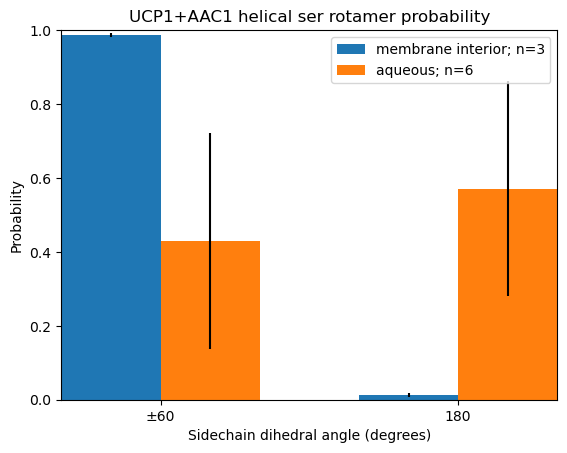

In [21]:
def plot_rotamers_2_sites(mean_std_rotamer_freqs, n_rotamers, n_resis_by_site, protein, resn):
    bar_width = 0.25
    gap_width = 0.25

    x = -bar_width/2
    
    site_inds = [0,1]
    rotamer_inds = [1,0]

    for rotamer in rotamer_inds:
        for site, color in zip(site_inds, ["C0","C1"]):

            plt.bar((x), (mean_std_rotamer_freqs[0,site,rotamer]), yerr=(mean_std_rotamer_freqs[1,site,rotamer]), width=bar_width, color = color)

            x += bar_width
        x += gap_width

    plt.xticks([0,0.75], ('±60', '180'))
    #offset = 1.5
    plt.xlim(-bar_width, 4*bar_width)
    plt.ylim(0,1)

    plt.ylabel("Probability")
    plt.xlabel("Sidechain dihedral angle (degrees)")
    plt.legend([f"membrane interior; n={n_resis_by_site[site_inds[0]]}", f"aqueous; n={n_resis_by_site[site_inds[1]]}"]) #, f"loop (aqueous); n={n_resis_by_site[site_inds[2]]}"])

    plt.title(f"{protein.upper()} helical {resn} rotamer probability")

    plt.savefig(f"figures/{protein}-{resn}-helix-pm60-rotamers.png", dpi=600)

    plt.show()

mean_std_rotamer_freqs = np.stack((means, stdevs))
plot_rotamers_2_sites(mean_std_rotamer_freqs, 2, n, "UCP1+AAC1", resn)

In [ ]:
# def rotamer_stats(helix_solv_rotamers, sitetypes, rotamertypes):
    
#     if sitetypes == "all":
#         helix_types = [0,2]
#         solv_types = [0,2]
#     elif sitetypes == "helixonly":
#         helix_types = [2]
#         solv_types = [0,2]

#     if rotamertypes == "all":
#         rotamergroups = [[0],[1],[2]]
#     elif rotamertypes == "180_pm60":
#         rotamergroups = [[0],[1,2]]

#     data_by_class = [[[] for b in range(len(rotamergroups))] for a in range(len(helix_types)*len(helix_types))]

#     print(data_by_class)

#     for r in helix_solv_rotamers:
#         data_by_class[r[]]

In [ ]:
    #     dG_all.append(dG)
    #     hbond_t_frac_all.append(hbond_t_frac)
    #     resseq_all += resseqs
    #     prot_all += [protein for x in range(len(resseqs))]

    #     # dG_dry, dG_wet, dG_interfacial = analysis_method(rotamer_data, hbond_data, helix_data)
    #     # dG_dry_all.append(dG_dry)
    #     # dG_wet_all.append(dG_wet)
    #     # dG_interfacial_all.append(dG_interfacial)

    # # print(list(dG_wet_all))
    # # print(list(dG_dry_all))
    # # print(list(dG_interfacial_all))

    # # dG_dry_all = np.concatenate(dG_dry_all)
    # # dG_wet_all = np.concatenate(dG_wet_all)
    # # dG_interfacial_all = np.concatenate(dG_interfacial_all)
    # print(dG_all)
    # print(hbond_t_frac_all)

    #     dG, hbond_t_frac, resseqs = analysis_method(rotamer_data, hbond_data, helix_data, resseqs)

    #     print(dG)
    #     print(hbond_t_frac)



    # dG_all = np.concatenate(dG_all)
    # hbond_t_frac_all = np.concatenate(hbond_t_frac_all)

    # return dG_all, hbond_t_frac_all, prot_all, resseq_all

    # dG_dry_all = []
    # dG_wet_all = []
    # dG_interfacial_all = []
    # dG_all = []
    # hbond_t_frac_all = []

    # resseq_all = []
    # prot_all = []

        #for x,y,z in zip(secstr[nr], rotamers[nr], hbonds[nr]):
        #    rotamer_hbonds[nr,y,z]+=1